In [1]:
# Cell 1 of 4 — which interpreter is this kernel running?
import sys
import platform
from pathlib import Path

executable = Path(sys.executable)

print("Python version :", sys.version.split()[0])
print("Executable     :", executable)
print("Platform       :", platform.system(), platform.release())
print("Working dir    :", Path.cwd())

in_venv = sys.base_prefix != sys.prefix
print("\nEnvironment root :", sys.prefix)
print("Base interpreter :", sys.base_prefix)
print("Running inside a virtual environment:", in_venv)

if in_venv and "venv" in str(executable):
    print("\nCorrect: the kernel is running from your course virtual environment.")
elif in_venv:
    print("\nA virtual environment is active, but its name is not 'venv'.")
else:
    print("\nWARNING: this kernel is NOT running inside a virtual environment.")

Python version : 3.13.7
Executable     : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/venv/bin/python
Platform       : Darwin 24.6.0
Working dir    : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/notebook

Environment root : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/venv
Base interpreter : /Library/Frameworks/Python.framework/Versions/3.13
Running inside a virtual environment: True

Correct: the kernel is running from your course virtual environment.


In [1]:
# Cell 2 of 4 — package availability and versions
import importlib

REQUIRED = ["numpy", "pandas", "matplotlib", "seaborn", "scipy"]
OPTIONAL = ["plotly", "openpyxl", "ipykernel"]

def check_packages(names):
    results = {}
    for name in names:
        try:
            module = importlib.import_module(name)
            results[name] = getattr(module, "__version__", "unknown")
        except ImportError:
            results[name] = None
    return results

required_status = check_packages(REQUIRED)
optional_status = check_packages(OPTIONAL)

print("REQUIRED PACKAGES")
for name, version in required_status.items():
    mark = "OK     " if version else "MISSING"
    print(f"  [{mark}] {name:<12} {version or '-- run: pip install ' + name}")

print("\nSUPPORTING PACKAGES")
for name, version in optional_status.items():
    mark = "OK     " if version else "missing"
    print(f"  [{mark}] {name:<12} {version or '-- run: pip install ' + name}")

missing_required = [n for n, v in required_status.items() if v is None]
if missing_required:
    print(f"\nInstall these first: {', '.join(missing_required)}")
else:
    print("\nSummary: environment ready.")
    

Matplotlib is building the font cache; this may take a moment.


REQUIRED PACKAGES
  [OK     ] numpy        2.5.4
  [OK     ] pandas       3.1.1
  [OK     ] matplotlib   3.11.2
  [OK     ] seaborn      0.13.2
  [OK     ] scipy        1.18.1

SUPPORTING PACKAGES
  [OK     ] plotly       7.1.0
  [OK     ] openpyxl     3.1.5
  [OK     ] ipykernel    7.4.0

Summary: environment ready.


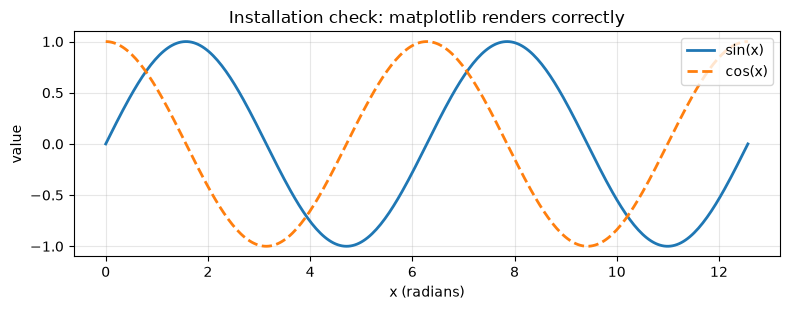

If a figure with two curves appears above, plotting is configured correctly.
The Jupyter extension displays figures inline; no extra configuration is needed.


In [2]:
# Cell 3 of 4 — confirm the plotting backend renders inside VS Code
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 4 * np.pi, 300)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(x, np.sin(x), label="sin(x)", linewidth=2)
ax.plot(x, np.cos(x), label="cos(x)", linewidth=2, linestyle="--")
ax.set_title("Installation check: matplotlib renders correctly")
ax.set_xlabel("x (radians)")
ax.set_ylabel("value")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("If a figure with two curves appears above, plotting is configured correctly.")
print("The Jupyter extension displays figures inline; no extra configuration is needed.")

In [3]:
# Cell 4 of 4 — confirm pandas can build, save and reload a table
import pandas as pd
from pathlib import Path

df = pd.DataFrame({
    "student_id": [1001, 1002, 1003, 1004],
    "name": ["Sophea", "Dara", "Chanthou", "Rithy"],
    "score": [78.5, 91.0, 66.25, 84.0],
    "passed": [True, True, True, True],
})

print("DataFrame created:")
print(df)

df.to_csv("setup_check.csv", index=False)
reloaded = pd.read_csv("setup_check.csv")
print("\nCSV round-trip successful:", reloaded.shape == df.shape)

Path("setup_check.csv").unlink()
print("Temporary file removed. pandas is working correctly.")

DataFrame created:
   student_id      name  score  passed
0        1001    Sophea  78.50    True
1        1002      Dara  91.00    True
2        1003  Chanthou  66.25    True
3        1004     Rithy  84.00    True

CSV round-trip successful: True
Temporary file removed. pandas is working correctly.


In [4]:
from pathlib import Path

folders = [
    "data/raw",
    "data/processed",
    "figures",
    "notebooks"
]

for folder in folders:
    path = Path(folder)
    path.mkdir(parents=True, exist_ok=True)
    print(f"Verified/Created folder: {folder}/")

print("\nProject folder structure setup complete.")

Verified/Created folder: data/raw/
Verified/Created folder: data/processed/
Verified/Created folder: figures/
Verified/Created folder: notebooks/

Project folder structure setup complete.


In [5]:
# Part 8 — Homework Problem 1: Environment Report Function
import sys
import platform
from pathlib import Path

def environment_report():
    """Returns a dictionary summarizing the current Python environment."""
    executable = Path(sys.executable)
    in_venv = sys.base_prefix != sys.prefix
    
    report = {
        "python_version": sys.version.split()[0],
        "executable": str(executable),
        "platform": f"{platform.system()} {platform.release()}",
        "working_directory": str(Path.cwd()),
        "in_virtual_env": in_venv,
        "environment_path": sys.prefix
    }
    return report

# Test the function
env_info = environment_report()
for key, value in env_info.items():
    print(f"{key:<20}: {value}")

python_version      : 3.13.7
executable          : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/venv/bin/python
platform            : Darwin 24.6.0
working_directory   : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/notebook
in_virtual_env      : True
environment_path    : /Users/ctrcomputer/Documents/Data Analysist and Virtualization_Homeworks/venv


In [6]:
# Part 8 — Homework Problem 2: Safe Division Function
def safe_divide(numerator, denominator):
    """Divides numerator by denominator safely, returning None if denominator is zero or inputs are invalid."""
    try:
        if denominator == 0:
            return None
        return numerator / denominator
    except TypeError:
        return None

# Test the function with various inputs
print("10 / 2 =", safe_divide(10, 2))      # Expected: 5.0
print("10 / 0 =", safe_divide(10, 0))      # Expected: None
print("'a' / 2 =", safe_divide("a", 2))    # Expected: None

10 / 2 = 5.0
10 / 0 = None
'a' / 2 = None
